## Part 3 — Machine Learning: Predict No-Shows

In this part, I build machine learning models to predict whether a patient will miss an appointment.

**Steps performed:**

1. Load the cleaned appointment dataset.
2. Select useful features and convert categorical values into numerical format.
3. Split the data into training (80%) and testing (20%).
4. Calculate baseline accuracy.
5. Train Logistic Regression and evaluate it using accuracy, precision, recall, F1-score and ROC-AUC.
6. Calculate feature coefficients and reminder odds ratios.
7. Create and compare Decision Trees with unlimited depth and depth 3 to understand overfitting.
8. Train a Random Forest and identify the most important features.
9. Create a comparison table to evaluate model performance.
10. Use GridSearchCV and cross-validation to tune and select the best model.
11. Compare probability thresholds (0.50 and 0.35) using precision, recall and F1-score.
12. Evaluate the selected model on the test set and save appointment risk scores in `test_risk_scores.csv`.

**Final Goal:** Identify high-risk appointments early so the clinic can contact patients and reduce missed appointments.

In [1]:
# @title Importing important libraries

# # Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import warnings
warnings.filterwarnings("ignore")

# Importing machine learning tools
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score, precision_score, recall_score, f1_score

In [2]:
# loading the "appoinments_clean.csv" file
df_clean = pd.read_csv("/content/appointments_clean.csv")
df_clean.head()

,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,A0001,P509,C05,2025-01-24,2025-01-25,60,F,18.0,850,Phone,Consultation,Yes,1,No-Show,1,1
1,A0002,P046,C07,2025-05-27,2025-06-06,39,M,12.5,350,Walk-In,Follow-up,No,2,Attended,10,0
2,A0003,P009,C02,2025-03-24,2025-03-30,63,F,4.1,850,Walk-In,Consultation,No,0,Attended,6,0
3,A0004,P482,C01,2025-04-18,2025-04-22,52,F,7.5,750,App,Consultation,Yes,0,Attended,4,0
4,A0005,P251,C01,2024-11-23,2025-01-02,64,F,19.0,700,Phone,Consultation,No,0,No-Show,40,1



## 3.1 Feature Selection and Train-Test Split

In this section, I prepare the cleaned appointment data for machine learning.

- Select the required five numerical features and two categorical features.
- Convert `reminder_sent` into numerical values (Yes = 1, No = 0).
- Apply one-hot encoding to `booking_channel` and `visit_type`.
- Separate the input features (X) and target variable (y).
- Split the data into 80% training and 20% testing using `random_state=42`.

The training data is used to build the models, while the testing data is used to evaluate their performance.


In [3]:
# Preparing model input features
X = df_clean[["age", "distance_km", "fee_inr", "lead_days","prior_no_shows","reminder_sent",'visit_type','booking_channel']].copy()
y = df_clean["no_show"]

In [4]:
# # Converting reminder labels
X['reminder_sent'] = X['reminder_sent'].map({'Yes': 1, 'No': 0})

In [5]:
# Applying one-hot encoding
X = pd.get_dummies(X, columns=["booking_channel","visit_type"])

In [6]:
print(X.head())
print(y.head())

   age  distance_km  fee_inr  lead_days  prior_no_shows  reminder_sent  \
0   60         18.0      850          1               1              1   
1   39         12.5      350         10               2              0   
2   63          4.1      850          6               0              0   
3   52          7.5      750          4               0              1   
4   64         19.0      700         40               0              0   

   booking_channel_App  booking_channel_Phone  booking_channel_Walk-In  \
0                False                   True                    False   
1                False                  False                     True   
2                False                  False                     True   
3                 True                  False                    False   
4                False                   True                    False   

   visit_type_Consultation  visit_type_Follow-up  
0                     True                 False  
1       

In [7]:
# Splitting training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# Checking dataset split sizes
print("Training size:", len(X_train))
print("Test size:", len(X_test))
print("Numbers of no_shows", y_test.sum())

Training size: 792
Test size: 198
Numbers of no_shows 49


In [9]:
# Calculating baseline accuracy
baseline_predictions = [0] * len(y_test)
baseline_accuracy = accuracy_score(y_test,baseline_predictions)
print("Baseline accuracy:", baseline_accuracy)

Baseline accuracy: 0.7525252525252525



## 3.2 Logistic Regression

In this section, I build a Logistic Regression model to predict whether a patient will miss an appointment.

- Apply StandardScaler to scale the features.
- Fit the scaler only on the training data and transform the testing data.
- Train the Logistic Regression model with `max_iter=1000`.
- Evaluate the model using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.
- Examine the model coefficients and calculate the reminder odds ratio.

The odds ratio helps us understand the association between appointment reminders and the likelihood of a no-show.


In [10]:
#  Logistic Regression

# Standardizing numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# Training logistic regression model
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [12]:
# Generating model predictions
y_pred_lr = lr.predict(X_test_scaled)
# Predicting no-show probabilities
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

In [13]:
# Evaluating classification performance
print("classification report")
print(classification_report(y_test, y_pred_lr))
print("confusion matrix")
print(confusion_matrix(y_test, y_pred_lr))
print("accuracy:",accuracy_score(y_test,y_pred_lr))
print("precision:" ,precision_score(y_test, y_pred_lr))
print("recall:" ,recall_score(y_test, y_pred_lr))
print("f1_score:" ,f1_score(y_test, y_pred_lr))
print("roc_auc_score:" ,roc_auc_score(y_test, y_prob_lr))

classification report
              precision    recall  f1-score   support

           0       0.81      0.93      0.87       149
           1       0.63      0.35      0.45        49

    accuracy                           0.79       198
   macro avg       0.72      0.64      0.66       198
weighted avg       0.77      0.79      0.76       198

confusion matrix
[[139  10]
 [ 32  17]]
accuracy: 0.7878787878787878
precision: 0.6296296296296297
recall: 0.3469387755102041
f1_score: 0.4473684210526316
roc_auc_score: 0.788933022873579


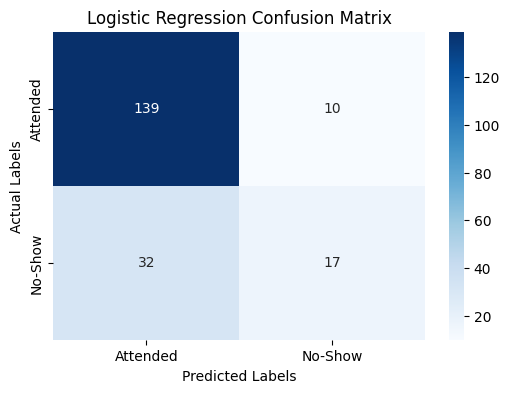

In [14]:
# Plotting confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Attended", "No-Show"],
            yticklabels=["Attended", "No-Show"])
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [15]:
# Displaying feature coefficients
feature_coff = pd.DataFrame({"feature": X_train.columns, "coefficient": lr.coef_[0]})
feature_coff

,feature,coefficient
0,age,-0.253880
1,distance_km,0.253448
2,fee_inr,0.452761
3,lead_days,0.614471
4,prior_no_shows,0.649612
5,reminder_sent,-0.580669
6,booking_channel_App,-0.046804
7,booking_channel_Phone,0.215881
8,booking_channel_Walk-In,-0.186364
9,visit_type_Consultation,0.015658


In [16]:
# Calculating reminder odds ratios
reminder_index = X.columns.get_loc("reminder_sent")
reminder_coefficient = lr.coef_[0][reminder_index]
odds_ratio_scaled = np.exp(reminder_coefficient)
odds_ratio_actual = np.exp( reminder_coefficient / scaler.scale_[reminder_index])

In [17]:
# Comparing reminder odds ratios
print("Odds Ratio (one standard deviation):", odds_ratio_scaled)
print("Odds Ratio (No to Yes reminder):", odds_ratio_actual)

Odds Ratio (one standard deviation): 0.559524141750829
Odds Ratio (No to Yes reminder): 0.3093980903124433



## 3.3 Decision Tree Models

In this section, I train and compare two Decision Tree models:

1. A Decision Tree without a maximum depth.
2. A Decision Tree with `max_depth=3`.

I compare their training and testing accuracy to understand how model complexity affects performance.

A large difference between training and testing accuracy may indicate overfitting.


In [18]:
#  Decision Tree Models

# Creating unrestricted decision tree
dt= DecisionTreeClassifier(random_state=42)

In [19]:
# Training unrestricted decision tree
dt.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [20]:
# Generating tree predictions
y_train_pred_dt= dt.predict(X_train_scaled)
y_test_pred_dt= dt.predict(X_test_scaled)

In [21]:
# Comparing training and test accuracy
train_accuracy = accuracy_score(y_train, y_train_pred_dt)
test_accuracy= accuracy_score(y_test, y_test_pred_dt)

In [22]:
# Displaying unrestricted tree results
print("Decision Tree (No Depth Limit)")
print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Decision Tree (No Depth Limit)
Training Accuracy: 1.0
Test Accuracy: 0.6717171717171717


In [23]:
# Creating depth-limited tree
dt_depth3= DecisionTreeClassifier(random_state=42 ,max_depth = 3)

In [24]:
# Training depth-limited tree
dt_depth3.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [25]:
# Generating depth-limited predictions
y_train_pred_dt2 = dt_depth3.predict(X_train_scaled)
y_test_pred_dt2= dt_depth3.predict(X_test_scaled)

In [26]:
# Comparing depth-limited accuracy
train_accuracy= accuracy_score(y_train, y_train_pred_dt2)
test_accuracy = accuracy_score(y_test, y_test_pred_dt2)

In [27]:
# Displaying depth-three results
print("Decision Tree (with max_depth = 3)")
print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Decision Tree (with max_depth = 3)
Training Accuracy: 0.821969696969697
Test Accuracy: 0.7777777777777778



## 3.4 Random Forest Model

In this section, I train a Random Forest classifier using 100 decision trees.

I evaluate the model using accuracy, precision, recall, F1-score and ROC-AUC. I also identify the three most important features using feature importance.

Finally, I compare Logistic Regression, the depth-3 Decision Tree and Random Forest to understand which model performs better.


In [28]:
# Random Forest Model

# Creating random forest classifier
rf = RandomForestClassifier(random_state=42, n_estimators= 100)

In [29]:
# Training random forest model
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [30]:
# Generating forest predictions
y_train_pred_rf= rf.predict(X_train_scaled)
y_test_pred_rf= rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

In [31]:
# Evaluating random forest accuracy
train_accuracy= accuracy_score(y_train, y_train_pred_rf)
test_accuracy = accuracy_score(y_test, y_test_pred_rf)

In [32]:
# Displaying random_forest performance
print("Random Forest (accuracy)")
print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)
print("precision:" ,precision_score(y_test, y_test_pred_rf))
print("recall:" ,recall_score(y_test, y_test_pred_rf))
print("f1_score:" ,f1_score(y_test, y_test_pred_rf))
print("roc_auc_score:" ,roc_auc_score(y_test, y_prob_rf))

Random Forest (accuracy)
Training Accuracy: 1.0
Test Accuracy: 0.7474747474747475
precision: 0.4838709677419355
recall: 0.30612244897959184
f1_score: 0.375
roc_auc_score: 0.7077112724284345


In [33]:
# Finding important features
importances = pd.DataFrame({"columns": X.columns ,"Feature_imp": rf.feature_importances_})
importances.sort_values("Feature_imp", ascending=False, inplace=True)
print(importances.head(3).round(2))

       columns  Feature_imp
3    lead_days         0.22
0          age         0.20
1  distance_km         0.19


In [34]:
# Comparing three machine learning models
model_name= pd.DataFrame({"models":["logistic_reg","DecisionTree", "RandomForest"]})
# Collecting model accuracy scores
accuracy_results = pd.DataFrame({
    "accuracy_score": [ accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_test_pred_dt2),accuracy_score(y_test, y_test_pred_rf)]
})

# Collecting model recall scores
recall_results = pd.DataFrame({
    "recall_score": [ recall_score(y_test, y_pred_lr),recall_score(y_test, y_test_pred_dt2), recall_score(y_test, y_test_pred_rf)]
})

# Collecting model ROC-AUC scores
roc_auc_results = pd.DataFrame({
    "roc_auc_score": [ roc_auc_score(y_test, y_prob_lr),roc_auc_score(y_test, dt_depth3.predict_proba(X_test_scaled)[:, 1]),roc_auc_score(y_test, y_prob_rf)]
})

# Creating model comparison table
models = pd.concat( [model_name, accuracy_results, recall_results, roc_auc_results], axis=1)
models.sort_values("roc_auc_score", ascending=False, inplace=True)
print(models)

         models  accuracy_score  recall_score  roc_auc_score
0  logistic_reg        0.787879      0.346939       0.788933
2  RandomForest        0.747475      0.306122       0.707711
1  DecisionTree        0.777778      0.224490       0.699699



## 3.5 Hyperparameter Tuning and Model Selection

In this section, I use GridSearchCV to find the best Random Forest hyperparameters.

- Test `n_estimators` values of 100 and 200.
- Test `max_depth` values of 3, 5 and 8.
- Use 5-fold cross-validation.
- Use ROC-AUC as the scoring metric.

I then compare the cross-validated ROC-AUC scores of Logistic Regression, the depth-3 Decision Tree, the original Random Forest and the tuned Random Forest.

The model with the highest cross-validated ROC-AUC is selected as the winning model.


In [35]:
# Model tuning and selection

# Importing cross-validation tools
from sklearn.model_selection import KFold, cross_val_score,cross_val_predict
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

In [36]:
# Defining random forest parameters
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), {"n_estimators": [100, 200], "max_depth": [3, 5, 8]}, cv=5, scoring="roc_auc")

In [37]:
# Searching best forest parameters
grid_rf.fit(X_train, y_train)
print("Best Parameters:", grid_rf.best_params_)
print("Best Score:", grid_rf.best_score_.round(2))

Best Parameters: {'max_depth': 3, 'n_estimators': 200}
Best Score: 0.77


In [38]:
# Comparing cross-validation scores

# Creating logistic regression pipeline
from sklearn.pipeline import Pipeline
lr_pipe = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000))])
# Calculating logistic regression CV score
lr_cv = cross_val_score(lr_pipe, X_train, y_train, cv=5, scoring="roc_auc").mean()
# Calculating depth-three tree CV score
dt_cv = cross_val_score(dt_depth3, X_train, y_train, cv=5, scoring="roc_auc").mean()
# Calculating random forest CV score
rf_cv = cross_val_score(rf, X_train, y_train, cv=5, scoring="roc_auc").mean()
# Retrieving tuned forest CV score
tuned_rf_cv = grid_rf.best_score_

In [39]:
# Displaying cross-validation scores
print("Logistic Regression CV ROC-AUC:", lr_cv.round(2))
print("Decision Tree CV ROC-AUC:", dt_cv.round(2))
print("Random Forest CV ROC-AUC:", rf_cv.round(2))
print("Tuned Random Forest CV ROC-AUC:", tuned_rf_cv.round(2))

Logistic Regression CV ROC-AUC: 0.77
Decision Tree CV ROC-AUC: 0.68
Random Forest CV ROC-AUC: 0.75
Tuned Random Forest CV ROC-AUC: 0.77


In [40]:
# Comparing cross-validation performance
models = pd.DataFrame({"models": ["Logistic Regression", "Decision Tree", "Random Forest", "Tuned Random Forest"], "ROC-AUC": [lr_cv, dt_cv, rf_cv, tuned_rf_cv]})
models.sort_values("ROC-AUC", ascending=False, inplace=True)
print(models)

                models   ROC-AUC
0  Logistic Regression  0.773714
3  Tuned Random Forest  0.767324
2        Random Forest  0.746602
1        Decision Tree  0.678449


In [41]:
# Selecting highest scoring model
scores = {"Logistic Regression": lr_cv,"Depth-3 Tree": dt_cv,"Random Forest": rf_cv,"Tuned Random Forest": tuned_rf_cv}
winner_name = max(scores, key=scores.get)
print("\nWinner:", winner_name)
print("Best CV ROC-AUC:", scores[winner_name])


Winner: Logistic Regression
Best CV ROC-AUC: 0.7737139899948249


In [42]:
# Storing candidate machine learning models
models = { "Logistic Regression": lr_pipe,"Depth-3 Tree": DecisionTreeClassifier(max_depth=3,random_state=42),
           "Random Forest": RandomForestClassifier( n_estimators=100,random_state=42),
           "Tuned Random Forest": grid_rf.best_estimator_}

# Selecting winning model
winner_model = models[winner_name]
print(winner_model)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])



### Probability Threshold Selection

In this step, I generate out-of-fold (OOF) probabilities for the selected winning model using the training data.

I compare two probability thresholds: 0.50 and 0.35.

For each threshold, I calculate:
- Precision
- Recall
- F1-score
- Number of appointments flagged as high risk

I select the threshold that gives the highest F1-score. This helps balance the identification of high-risk appointments with the number of patients the call-centre team can follow up.


In [43]:
# Generating out-of-fold predictions
cv_auc = cross_val_score(winner_model, X_train, y_train, cv=5, scoring="roc_auc").mean()
oof = cross_val_predict(winner_model, X_train, y_train, cv=5, method="predict_proba")[:, 1]

# Fitting pipeline on training data
lr_pipe.fit(X_train, y_train)
probs = lr_pipe.predict_proba(X_test)[:, 1]

# Comparing classification thresholds
print("CV ROC-AUC:", cv_auc.round(2))
print("OOF ROC-AUC:", roc_auc_score(y_train, oof).round(2))
print("Test ROC-AUC:", roc_auc_score(y_test, probs).round(2))

CV ROC-AUC: 0.77
OOF ROC-AUC: 0.77
Test ROC-AUC: 0.79


In [44]:
# Evaluating different probability thresholds
thresholds = [0.5,0.35]

# Storing threshold evaluation results
threshold_results = []

# Testing each probability threshold
for threshold in thresholds:
    y_pred = (oof >= threshold).astype(int)
    precision = precision_score(y_train, y_pred)
    recall = recall_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)
    number_flagged = (y_pred == 1).sum()
    threshold_results.append((threshold, precision, recall, f1,number_flagged))

In [45]:
# Creating threshold comparison table
df_threshold_results = pd.DataFrame(threshold_results, columns=["Threshold", "Precision", "Recall", "F1 Score","number_flagged"])
print(df_threshold_results)

   Threshold  Precision    Recall  F1 Score  number_flagged
0       0.50   0.575342  0.248521  0.347107              73
1       0.35   0.512987  0.467456  0.489164             154


In [46]:
# Selecting threshold with highest F1
best_treshold = df_threshold_results.loc[df_threshold_results['F1 Score'].idxmax()]
print("Best Threshold:", best_treshold["Threshold"])
print("Best F1 Score:", best_treshold["F1 Score"])

Best Threshold: 0.35
Best F1 Score: 0.4891640866873065



### Final Model Evaluation and Risk Score Export

After selecting the winning model and probability threshold, I train the model on the complete training dataset and evaluate it on the test dataset.

I calculate the final precision, recall, F1-score and ROC-AUC. I also count the number of appointments flagged as high risk.

Finally, I export the test predictions into `test_risk_scores.csv` with the following columns:

- `appointment_id`
- `no_show`
- `risk_prob`
- `flag`

This file contains the predicted no-show risk for each appointment in the test dataset.


In [47]:
# Final model evaluation

# Training selected winning model
winner_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])

In [48]:
# Predicting final test probabilities
y_prob = winner_model.predict_proba(X_test)[:, 1]

# Applying selected probability threshold
y_pred = (y_prob >= best_treshold["Threshold"]).astype(int)

In [49]:
# Displaying final test performance
print("\nFinal Test Results")
print("best Model:", winner_name)
print("winner Threshold:", best_treshold["Threshold"])


Final Test Results
best Model: Logistic Regression
winner Threshold: 0.35


In [50]:
# Calculating final test metrics
print("\nfinal_model_precision :" ,precision_score(y_test, y_pred))
print("final_model_recall :" ,recall_score(y_test, y_pred))
print("final_model_f1_score :" ,f1_score(y_test, y_pred))
print("final_model_roc_auc_score :" ,roc_auc_score(y_test, y_prob))
print("final_model_number_flagged :" ,(y_pred == 1).sum())


final_model_precision : 0.5714285714285714
final_model_recall : 0.5714285714285714
final_model_f1_score : 0.5714285714285714
final_model_roc_auc_score : 0.788933022873579
final_model_number_flagged : 49


In [51]:
# Preparing final risk score dataset
appoinments_ids = df_clean['appointment_id']
test_risk_score = pd.DataFrame({
    "appointment_id": appoinments_ids.loc[X_test.index],
    "no_show":y_test,
    "risk_prob": y_prob.round(3),
    "flag": y_pred
})

In [54]:
# Displaying generated risk scores
print(test_risk_score)

    appointment_id  no_show  risk_prob  flag
213          A0217        0      0.022     0
331          A0336        0      0.151     0
501          A0508        0      0.519     1
309          A0314        0      0.191     0
88           A0089        0      0.168     0
..             ...      ...        ...   ...
450          A0456        1      0.320     0
705          A0715        0      0.146     0
305          A0310        0      0.163     0
807          A0818        1      0.401     1
237          A0241        0      0.101     0

[198 rows x 4 columns]


In [55]:
# Saving final risk score CSV
test_risk_score.to_csv("test_risk_scores.csv",index=False)
print("File saved: test_risk_scores.csv")

File saved: test_risk_scores.csv
